# Segmentación de clientes mayoristas

**Estudiante:** Jorge Adalberto Zuñiga Oliva  
**Matrícula:** 82005 · **Grupo:** 512  
**Materia:** Tópicos de Big Data

In [1]:
from pathlib import Path
import sys
RAIZ = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "scripts/curso.py").exists())
sys.path.insert(0, str(RAIZ / "scripts"))
from curso import (leer_owid, metadatos, indicador, solo_paises, guardar_figura,
                   guardar_tabla, U1, U3, SALIDA, FUENTES)
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
pd.set_option("display.max_rows", 12)
pd.set_option("display.max_columns", 12)

## 1. Fuente y unidad de observación
Se utiliza Wholesale Customers de UCI: una fila representa un cliente y sus gastos anuales
en seis categorías, en unidades monetarias. `Channel` y `Region` son categorías y se reservan
para describir grupos. Se añade un identificador de fila solo para rastrear resultados.
Cardoso, M. (2013). [UCI, DOI 10.24432/C5030X](https://archive.ics.uci.edu/dataset/292/wholesale+customers).

In [2]:
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.decomposition import PCA
from sklearn.neighbors import NearestNeighbors
datos = pd.read_csv(FUENTES / "uci/wholesale_customers.csv")
gastos = ["Fresh", "Milk", "Grocery", "Frozen", "Detergents_Paper", "Delicassen"]
print("Dimensiones:", datos.shape)
display(datos.head())
display(datos.isna().sum().to_frame("faltantes"))
display(datos[gastos].describe().round(1))
assert datos[gastos].notna().all().all() and datos[gastos].ge(0).all().all()
datos["cliente_fila"] = np.arange(1, len(datos)+1)

Dimensiones: (440, 8)


,Channel,Region,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen
0,2,3,12669,9656,7561,214,2674,1338
1,2,3,7057,9810,9568,1762,3293,1776
2,2,3,6353,8808,7684,2405,3516,7844
3,1,3,13265,1196,4221,6404,507,1788
4,2,3,22615,5410,7198,3915,1777,5185


,faltantes
Channel,0
Region,0
Fresh,0
Milk,0
Grocery,0
Frozen,0
Detergents_Paper,0
Delicassen,0


,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen
count,440.0,440.0,440.0,440.0,440.0,440.0
mean,12000.3,5796.3,7951.3,3071.9,2881.5,1524.9
std,12647.3,7380.4,9503.2,4854.7,4767.9,2820.1
min,3.0,55.0,3.0,25.0,3.0,3.0
25%,3127.8,1533.0,2153.0,742.2,256.8,408.2
50%,8504.0,3627.0,4755.5,1526.0,816.5,965.5
75%,16933.8,7190.2,10655.8,3554.2,3922.0,1820.2
max,112151.0,73498.0,92780.0,60869.0,40827.0,47943.0


## 2. Transformar y escalar
El gasto tiene asimetría y valores muy grandes. `log1p` permite ceros y comprime extremos;
después cada categoría se estandariza para que su escala no domine la distancia.
Se conservan clientes extremos porque el importe alto puede ser válido.

,media_transformada,desviacion_transformada
Fresh,0.0,1.0
Milk,-0.0,1.0
Grocery,-0.0,1.0
Frozen,0.0,1.0
Detergents_Paper,-0.0,1.0
Delicassen,-0.0,1.0


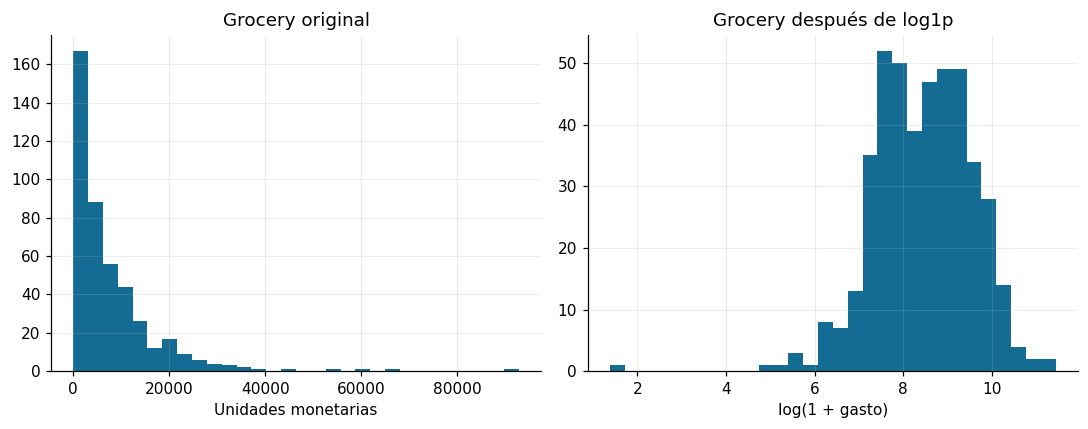

In [3]:
log_gastos = np.log1p(datos[gastos])
escalador = StandardScaler()
X = escalador.fit_transform(log_gastos)
display(pd.DataFrame({"media_transformada": X.mean(axis=0), "desviacion_transformada": X.std(axis=0)}, index=gastos).round(4))
fig, ejes = plt.subplots(1, 2, figsize=(10, 4))
ejes[0].hist(datos.Grocery, bins=30); ejes[0].set(title="Grocery original", xlabel="Unidades monetarias")
ejes[1].hist(log_gastos.Grocery, bins=30); ejes[1].set(title="Grocery después de log1p", xlabel="log(1 + gasto)")
guardar_figura("U4_1_transformacion")

## 3. Comparar k con inercia y silueta
La inercia siempre favorece aumentar k. La silueta compara cohesión y separación, por lo
que sirve como otro criterio. Aquí se elige su máximo entre 2 y 8 como regla explícita,
y se revisan tamaños y perfiles; no se afirma que exista un único número verdadero de grupos.

,k,inercia,silueta
0,2,1844.0641,0.2903
1,3,1553.3819,0.2585
2,4,1386.8627,0.1885
3,5,1266.1494,0.1916
4,6,1174.4022,0.1931
5,7,1086.3980,0.1954
6,8,1028.4924,0.1912


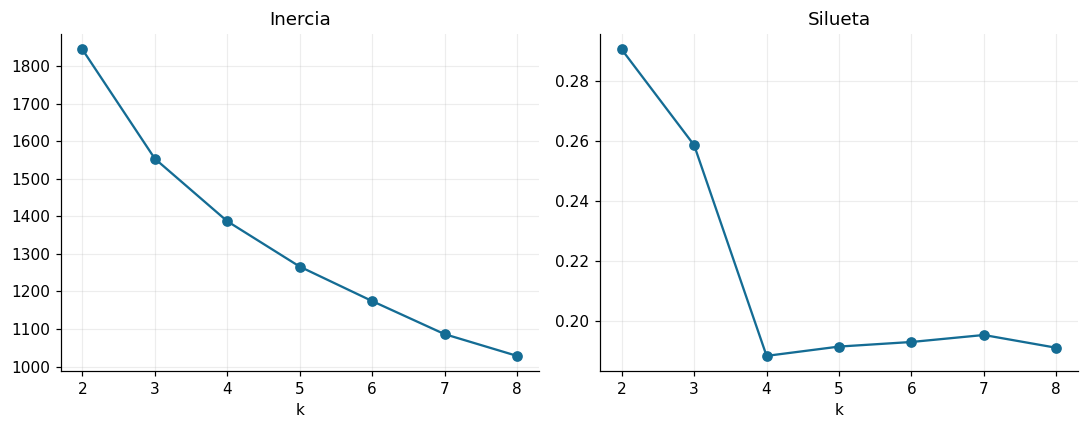

In [4]:
candidatos = []
for k in range(2, 9):
    modelo = KMeans(n_clusters=k, n_init=20, random_state=82005)
    etiquetas = modelo.fit_predict(X)
    candidatos.append({"k": k, "inercia": modelo.inertia_, "silueta": silhouette_score(X, etiquetas)})
evaluacion = pd.DataFrame(candidatos)
display(evaluacion.round(4))
elegido = int(evaluacion.loc[evaluacion.silueta.idxmax(), "k"])
modelo = KMeans(n_clusters=elegido, n_init=20, random_state=82005)
datos["grupo"] = modelo.fit_predict(X)
fig, ejes = plt.subplots(1, 2, figsize=(10, 4))
ejes[0].plot(evaluacion.k, evaluacion.inercia, "o-"); ejes[0].set(title="Inercia", xlabel="k")
ejes[1].plot(evaluacion.k, evaluacion.silueta, "o-"); ejes[1].set(title="Silueta", xlabel="k")
guardar_figura("U4_1_eleccion_k")

## 4. Perfiles en unidades originales y vista PCA
El PCA se usa para dibujar dos componentes después de agrupar con las seis variables.
No se reentrena K-Means en dos dimensiones. Se informa la proporción de variación conservada.

,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen
grupo,,,,,,
0,5406.5,7690.5,11527.0,1061.5,4495.0,1388.5
1,10347.5,1871.0,2406.0,2225.0,327.5,749.5


,clientes,porcentaje
grupo,,
0,188,42.7
1,252,57.3


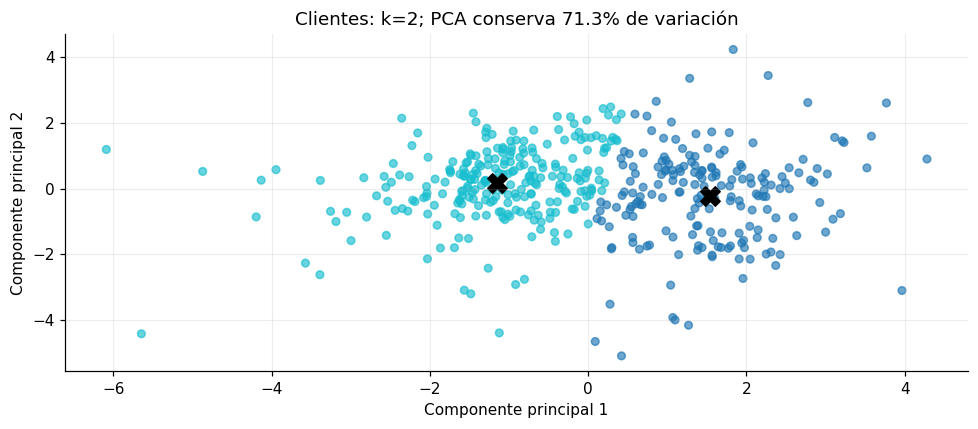

CSV guardado: U3_1_modelos_ml/data/processed/wholesale_clientes_segmentados.csv (440 filas)
CSV guardado: U3_1_modelos_ml/data/processed/wholesale_perfiles.csv (2 filas)
CSV guardado: U3_1_modelos_ml/data/processed/wholesale_eleccion_k.csv (7 filas)


In [5]:
perfiles = datos.groupby("grupo")[gastos].median()
tamanos = datos.groupby("grupo").size().rename("clientes")
display(perfiles.round(1))
display(tamanos.to_frame().assign(porcentaje=100*tamanos/len(datos)).round(1))
pca = PCA(n_components=2)
coordenadas = pca.fit_transform(X)
plt.scatter(coordenadas[:, 0], coordenadas[:, 1], c=datos.grupo, cmap="tab10", alpha=.65, s=25)
centros = pca.transform(modelo.cluster_centers_)
plt.scatter(centros[:, 0], centros[:, 1], color="black", marker="X", s=160)
plt.xlabel("Componente principal 1"); plt.ylabel("Componente principal 2")
plt.title(f"Clientes: k={elegido}; PCA conserva {pca.explained_variance_ratio_.sum():.1%} de variación")
guardar_figura("U4_1_pca")
guardar_tabla(datos, "wholesale_clientes_segmentados.csv")
guardar_tabla(perfiles.reset_index(), "wholesale_perfiles.csv")
guardar_tabla(evaluacion, "wholesale_eleccion_k.csv")

## 5. Consulta de vecinos
`NearestNeighbors` encuentra clientes similares a uno elegido en el mismo espacio escalado;
se excluye el propio cliente. Es una búsqueda de similitud, no un clasificador KNN ni un
nuevo entrenamiento de K-Means.

In [6]:
consulta = 0
buscador = NearestNeighbors(n_neighbors=6).fit(X)
distancias, indices = buscador.kneighbors(X[[consulta]])
vecinos = pd.DataFrame({"fila": indices[0], "distancia": distancias[0]})
vecinos = vecinos.loc[vecinos.fila.ne(consulta)].head(5)
display(vecinos.merge(datos, left_on="fila", right_index=True)[["cliente_fila", "distancia", "grupo", *gastos]])
for grupo in perfiles.index:
    razones = perfiles.loc[grupo] / datos[gastos].median()
    dominante = razones.idxmax()
    display(Markdown(f"El grupo **{grupo}** reúne **{int(tamanos[grupo])} clientes**. "
        f"Su categoría relativamente más destacada es **{dominante}**, con una mediana "
        f"{razones[dominante]:.2f} veces la mediana global de esa categoría."))

,cliente_fila,distancia,grupo,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen
1,15,0.850902,0,24653,9465,12091,294,5058,2168
2,60,0.851257,0,6137,5360,8040,129,3084,1603
3,181,0.961821,0,12356,6036,8887,402,1382,2794
4,418,1.002496,0,5065,5499,11055,364,3485,1063
5,6,1.012189,0,9413,8259,5126,666,1795,1451


El grupo **0** reúne **188 clientes**. Su categoría relativamente más destacada es **Detergents_Paper**, con una mediana 5.51 veces la mediana global de esa categoría.

El grupo **1** reúne **252 clientes**. Su categoría relativamente más destacada es **Frozen**, con una mediana 1.46 veces la mediana global de esa categoría.

## 6. Respuestas
1. **Identificador:** la numeración de clientes no mide parecido comercial y no entra al modelo.
2. **Escalas:** sin transformación, importes elevados dominarían la distancia euclidiana.
3. **Perfiles:** se interpretan con medianas originales y tamaños, no con el número de etiqueta.
4. **PCA:** pierde parte de la información; la proporción conservada aparece en el título.
5. **Vecinos y grupos:** vecinos responden a una consulta local; K-Means organiza todos los clientes.
6. **Alternativas:** comparar gasto relativo por categoría, otros escalados o algoritmos y
   estabilidad de segmentos con otras semillas. Eso cambiaría la pregunta o geometría del análisis.
[Referencia de clustering](https://scikit-learn.org/stable/modules/clustering.html#k-means).